# Decision Tree and Random Forest: tuning and scikit-learn counterparts

This notebook tunes the from-scratch ID3 and Random Forest on the validation split, compares them with their scikit-learn counterparts on the validation split, and checks that every model can be saved and loaded (spec point 9). The final test-set comparison of all models is in `comparison.ipynb`.

In [1]:
import os
import pickle
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

NOTEBOOK_DIR = os.path.abspath('.')
SRC_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..', 'src'))
SPLIT_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..', 'data'))
MODEL_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..', 'models'))
FIGURE_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..', 'doc', 'figures'))
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)
sys.path.insert(0, SRC_DIR)

from id3 import ID3
from random_forest import RandomForest
from evaluate import evaluate

print('split files found:', sorted(os.listdir(SPLIT_DIR)))

split files found: ['feature_names.csv', 'kaggle_test_preprocessed.csv', 'test_preprocessed.csv', 'train_preprocessed.csv', 'validation_preprocessed.csv']


## Load the shared split

The labels are mapped to numbers: Dropout = 0, Enrolled = 1, Graduate = 2.

In [2]:
LABEL_MAP = {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
CLASSES = [0, 1, 2]

train_frame = pd.read_csv(os.path.join(SPLIT_DIR, 'train_preprocessed.csv'))
X_train = train_frame.drop(columns=['Student_ID', 'Target']).to_numpy()
y_train = train_frame['Target'].map(LABEL_MAP).to_numpy()

validation_frame = pd.read_csv(os.path.join(SPLIT_DIR, 'validation_preprocessed.csv'))
X_val = validation_frame.drop(columns=['Student_ID', 'Target']).to_numpy()
y_val = validation_frame['Target'].map(LABEL_MAP).to_numpy()

print('train', X_train.shape, 'validation', X_val.shape)

train (1857, 211) validation (619, 211)


## Tuning ID3 max_depth on the validation split

Each depth is trained on the training split and scored on the validation split only. Macro F1 is the selection metric because the three classes are not balanced.

In [3]:
depth_values = [3, 5, 8, 12, None]
depth_labels = []
depth_f1 = []

for depth in depth_values:
    model = ID3(max_depth=depth, random_state=0)
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)
    results = evaluate(y_val, predictions, 0, 0, CLASSES)
    depth_labels.append(str(depth))
    depth_f1.append(results['macro_f1'])
    print('max_depth', depth, 'validation macro F1', round(results['macro_f1'], 4))

best_index = int(np.argmax(depth_f1))
best_depth = depth_values[best_index]
print('best max_depth:', best_depth)

max_depth 3 validation macro F1 0.6164


max_depth 5 validation macro F1 0.5689


max_depth 8 validation macro F1 0.608


max_depth 12 validation macro F1 0.6314


max_depth None validation macro F1 0.6284
best max_depth: 12


## Tuning Random Forest n_trees on the validation split

In [4]:
tree_values = [10, 25, 50, 100]
tree_f1 = []

for number_of_trees in tree_values:
    model = RandomForest(n_trees=number_of_trees, random_state=0)
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)
    results = evaluate(y_val, predictions, 0, 0, CLASSES)
    tree_f1.append(results['macro_f1'])
    print('n_trees', number_of_trees, 'validation macro F1', round(results['macro_f1'], 4))

best_index = int(np.argmax(tree_f1))
best_trees = tree_values[best_index]
print('best n_trees:', best_trees)

n_trees 10 validation macro F1 0.5711


n_trees 25 validation macro F1 0.638


n_trees 50 validation macro F1 0.6669


n_trees 100 validation macro F1 0.6733
best n_trees: 100


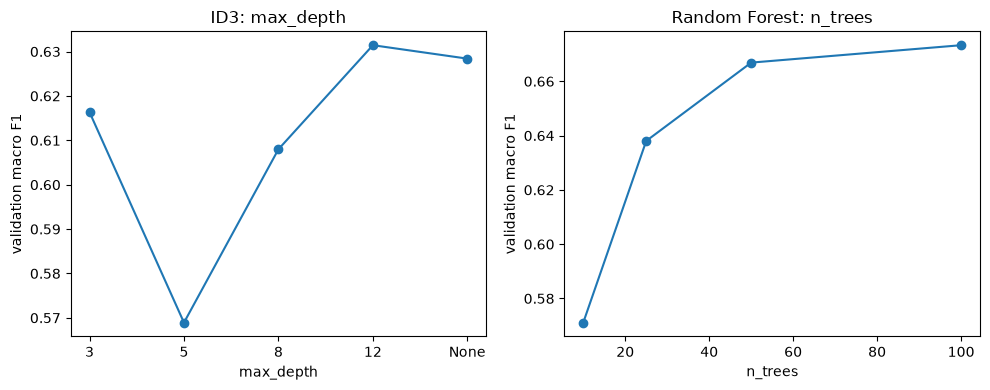

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(depth_labels, depth_f1, marker='o')
axes[0].set_title('ID3: max_depth')
axes[0].set_xlabel('max_depth')
axes[0].set_ylabel('validation macro F1')

axes[1].plot(tree_values, tree_f1, marker='o')
axes[1].set_title('Random Forest: n_trees')
axes[1].set_xlabel('n_trees')
axes[1].set_ylabel('validation macro F1')

figure.tight_layout()
figure.savefig(os.path.join(FIGURE_DIR, 'tuning_id3_rf.png'), dpi=150)
plt.show()

## From scratch vs scikit-learn on the validation split

The tuned values are used for both the from-scratch models and their scikit-learn counterparts.

In [6]:
model_names = ['ID3 from scratch', 'RF from scratch', 'sklearn DT (entropy)', 'sklearn RF (entropy)']
models = []
models.append(ID3(max_depth=best_depth, random_state=0))
models.append(RandomForest(n_trees=best_trees, random_state=0))
models.append(DecisionTreeClassifier(criterion='entropy', max_depth=best_depth, random_state=0))
models.append(RandomForestClassifier(n_estimators=best_trees, criterion='entropy', random_state=0))

rows = []
for i in range(len(models)):
    start = time.perf_counter()
    models[i].fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    start = time.perf_counter()
    predictions = models[i].predict(X_val)
    inference_seconds = time.perf_counter() - start

    results = evaluate(y_val, predictions, fit_seconds, inference_seconds, CLASSES)
    row = {}
    row['model'] = model_names[i]
    row['accuracy'] = round(results['accuracy'], 4)
    row['macro_f1'] = round(results['macro_f1'], 4)
    row['fit_s'] = round(results['fit_seconds'], 2)
    row['infer_s'] = round(results['inference_seconds'], 3)
    rows.append(row)

pd.DataFrame(rows)

,model,accuracy,macro_f1,fit_s,infer_s
0,ID3 from scratch,0.6995,0.6314,3.63,0.008
1,RF from scratch,0.7690,0.6733,51.82,1.058
2,sklearn DT (entropy),0.6914,0.6208,0.05,0.001
3,sklearn RF (entropy),0.7706,0.6719,0.34,0.016


## Save and load (spec point 9)

The from-scratch models use their own `save` and `load` methods. The scikit-learn models are saved with pickle. Each loaded model must give the same predictions as the original.

In [7]:
file_names = ['id3.pkl', 'random_forest.pkl', 'sklearn_dt_entropy.pkl', 'sklearn_rf_entropy.pkl']

for i in range(len(models)):
    path = os.path.join(MODEL_DIR, file_names[i])
    if i == 0:
        models[i].save(path)
        loaded = ID3.load(path)
    elif i == 1:
        models[i].save(path)
        loaded = RandomForest.load(path)
    else:
        with open(path, 'wb') as file:
            pickle.dump(models[i], file)
        with open(path, 'rb') as file:
            loaded = pickle.load(file)
    before = models[i].predict(X_val)
    after = loaded.predict(X_val)
    print(model_names[i], 'saved to', file_names[i], 'identical predictions after load:', bool(np.array_equal(before, after)))

ID3 from scratch saved to id3.pkl identical predictions after load: True


RF from scratch saved to random_forest.pkl identical predictions after load: True
sklearn DT (entropy) saved to sklearn_dt_entropy.pkl identical predictions after load: True
sklearn RF (entropy) saved to sklearn_rf_entropy.pkl identical predictions after load: True
